### 1. text -> token ID

In [3]:
from transformers import AutoTokenizer

# Load a tokenizer (using a small Qwen3 model)
model_name = "Qwen/Qwen3-0.6B"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Example sentence
text = "the cat is orange"

print(f"Using tokenizer from: {model_name}\n")
print("Original text:")
print(f"  '{text}'\n")

# Step 1: Break into tokens
tokens = tokenizer.tokenize(text)
print("Step 1 - Tokens (small pieces of text):")
print(f"  {tokens}\n")
print("  --> The 'Ġ' symbol represents a SPACE before the token")
print("      So 'Ġcat' means ' cat' (space + cat)\n")

# Step 2: Convert to token IDs
token_ids = tokenizer.encode(text)
print("Step 2 - Token IDs (numbers the model uses):")
print(f"  {token_ids}\n")

print("💡 The tokenizer converted 'the cat is orange' into numbers!")
print("   Now the transformer can process them.")

Using tokenizer from: Qwen/Qwen3-0.6B

Original text:
  'the cat is orange'

Step 1 - Tokens (small pieces of text):
  ['the', 'Ġcat', 'Ġis', 'Ġorange']

  --> The 'Ġ' symbol represents a SPACE before the token
      So 'Ġcat' means ' cat' (space + cat)

Step 2 - Token IDs (numbers the model uses):
  [1782, 8251, 374, 18575]

💡 The tokenizer converted 'the cat is orange' into numbers!
   Now the transformer can process them.


In [4]:
# Compare tokenization of different sentences
sentences = [
    "the cat is orange",
    "the cat is tabby",
    "the cat is underweight"
]

print(f"Tokenization with {model_name}:\n")

for sentence in sentences:
    tokens = tokenizer.tokenize(sentence)
    token_ids = tokenizer.encode(sentence)
    
    print(f"Sentence: '{sentence}'")
    print(f"  Tokens: {tokens}")
    print(f"  Token IDs: {token_ids}\n")

Tokenization with Qwen/Qwen3-0.6B:

Sentence: 'the cat is orange'
  Tokens: ['the', 'Ġcat', 'Ġis', 'Ġorange']
  Token IDs: [1782, 8251, 374, 18575]

Sentence: 'the cat is tabby'
  Tokens: ['the', 'Ġcat', 'Ġis', 'Ġtab', 'by']
  Token IDs: [1782, 8251, 374, 5651, 1694]

Sentence: 'the cat is underweight'
  Tokens: ['the', 'Ġcat', 'Ġis', 'Ġunder', 'weight']
  Token IDs: [1782, 8251, 374, 1212, 4765]



### 2. token ID -> embedding

In [9]:
from huggingface_hub import constants, try_to_load_from_cache

print("Hub 缓存目录：", constants.HF_HUB_CACHE)

path = try_to_load_from_cache(
    "Qwen/Qwen3-0.6B", "model.safetensors"
)
print("权重文件：", path)
from transformers.utils.hub import TRANSFORMERS_CACHE
print("Transformers 缓存目录：", TRANSFORMERS_CACHE)

Hub 缓存目录： /workspace/.cache/huggingface/hub
权重文件： None
Transformers 缓存目录： /workspace/.cache/huggingface/transformers


In [11]:
from transformers import AutoModel
import torch

# Load a modern transformer model (Qwen3 from 2024)
model_name = "Qwen/Qwen3-0.6B"
cache_dir = "/root/.cache/huggingface/hub"
print(f"Loading {model_name}...")
model = AutoModel.from_pretrained(model_name,  cache_dir=cache_dir)
tokenizer = AutoTokenizer.from_pretrained(model_name)
print("✓ Model loaded!\n")

# Get the token IDs for our sentence
text = "the cat is orange"
token_ids = tokenizer.encode(text, return_tensors="pt")

print(f"Text: '{text}'\n")
print(f"Token IDs shape: {token_ids.shape}")
print(f"  → {token_ids.shape[1]} tokens\n")

# Get embeddings from the model's embedding layer
with torch.no_grad():
    # The embedding layer converts token IDs to vectors
    # 
    embedding_layer = model.get_input_embeddings()
    embeddings = embedding_layer(token_ids)

print(f"Embeddings shape: {embeddings.shape}")
print(f"  → {embeddings.shape[1]} tokens")
print(f"  → {embeddings.shape[2]} dimensions per token")
print(f"\n💡 Each token ID became a {embeddings.shape[2]}-dimensional vector!")

Loading Qwen/Qwen3-0.6B...


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

✓ Model loaded!

Text: 'the cat is orange'

Token IDs shape: torch.Size([1, 4])
  → 4 tokens

Embeddings shape: torch.Size([1, 4, 1024])
  → 4 tokens
  → 1024 dimensions per token

💡 Each token ID became a 1024-dimensional vector!


In [26]:
import torch.nn.functional as F

# Get the embedding layer
embedding_layer = model.get_input_embeddings()

# Function to get embedding for a single word
def get_word_embedding(word):
    token_id = tokenizer.encode(word, add_special_tokens=False)[0]
    embedding = embedding_layer(torch.tensor([[token_id]]))
    return embedding[0, 0]  # [1, 1, 1024] -> [1024]

# Compare words from different categories
words_animals = ["cat", "dog"]
words_colors = ["red", "blue"]
words_countries = ["India", "Canada"]

all_words = words_animals + words_colors + words_countries
word_embeddings = {word: get_word_embedding(word) for word in all_words}

print("Let's compare words from DIFFERENT categories:\n")

# Compare cat (animal) to other words
cat_embedding = word_embeddings["cat"]

print("How similar are these words to 'cat' (an animal)?\n")
for word in all_words:
    if word == "cat":
        continue
    similarity = F.cosine_similarity(
        cat_embedding.unsqueeze(0),
        word_embeddings[word].unsqueeze(0)
    ).item()
    
    category = ""
    if word in words_animals:
        category = "(animal)"
    elif word in words_colors:
        category = "(color)"
    elif word in words_countries:
        category = "(country)"
    
    print(f"  cat ↔ {word:10s} {category:10s}: {similarity:.3f}")

print("\n💡:")
print("   • 'dog' (another animal) is the most similar to 'cat'")
print("   • Colors and countries are less similar to 'cat'")
print("   • Embeddings encode aspects of a token's meaning as a vector of numbers")

Let's compare words from DIFFERENT categories:

How similar are these words to 'cat' (an animal)?

  cat ↔ dog        (animal)  : 0.287
  cat ↔ red        (color)   : 0.083
  cat ↔ blue       (color)   : 0.053
  cat ↔ India      (country) : 0.008
  cat ↔ Canada     (country) : 0.057

💡:
   • 'dog' (another animal) is the most similar to 'cat'
   • Colors and countries are less similar to 'cat'
   • Embeddings encode aspects of a token's meaning as a vector of numbers


### 3. embedding -> context-aware repressention

In [58]:
from transformers import AutoModel, AutoTokenizer
import torch
import torch.nn.functional as F

# Load model
# model_name = "Qwen/Qwen3-0.6B"
# tokenizer = AutoTokenizer.from_pretrained(model_name)
# model = AutoModel.from_pretrained(model_name)

# Compare the same word "bank" in different contexts
sentences = [
    "I went to the bank",        # bank = financial institution
    "I sat by the river bank"    # bank = edge of river
]

representations = []

for sentence in sentences:
    inputs = tokenizer(sentence, return_tensors="pt")

    # Get contextual representation AFTER attention
    with torch.no_grad():
        outputs = model(**inputs)

    # Find "bank" token and get its vector
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    for i, token in enumerate(tokens):
        if "bank" in token.lower():
            bank_idx = i
            break
    representations.append(outputs.last_hidden_state[0, bank_idx])

    print(f"'{sentence}'")

# Compare the two "bank" vectors
similarity = F.cosine_similarity(
    representations[0].unsqueeze(0),
    representations[1].unsqueeze(0)
).item()

print(f"\nSimilarity between the two 'bank' vectors: {similarity:.3f}")
print("\n💡 Same word, different contexts → different vectors!")
print("   Attention lets each word look at other tokens in the sequence to understand its meaning.")

'I went to the bank'
'I sat by the river bank'

Similarity between the two 'bank' vectors: 0.732

💡 Same word, different contexts → different vectors!
   Attention lets each word look at other tokens in the sequence to understand its meaning.


### 4. repressention -> output

### 4.1 Causal Language Modeling

In [150]:
# Demonstrating one-token-at-a-time generation
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "Qwen/Qwen3-0.6B"
cache_dir = "/root/.cache/huggingface/hub"
tokenizer = AutoTokenizer.from_pretrained(model_name,  cache_dir=cache_dir)
model = AutoModelForCausalLM.from_pretrained(model_name,  cache_dir=cache_dir)

# Start with our prompt
text = "The weather today is"
print(f"Starting text: '{text}'\n")

# Generate 5 tokens, showing the process
for step in range(5):
    # Tokenize current text
    inputs = tokenizer(text, return_tensors="pt")
    
    # Get model predictions
    with torch.no_grad():
        outputs = model(**inputs)
    
    # Get predictions for the NEXT token
    next_token_logits = outputs.logits[0, -1, :]
    
    # Get the most likely next token
    next_token_id = next_token_logits.argmax()
    next_token = tokenizer.decode(next_token_id)
    
    # Add it to our text
    text += next_token
    
    print(f"Step {step + 1}: Added '{next_token}' → '{text}'")

print("\n💡 This is how modern language models generate text: one token at a time.")
print("   At each step, the model predicts the next token based on all previous tokens.")

Starting text: 'The weather today is'

Step 1: Added ' ' → 'The weather today is '
Step 2: Added '2' → 'The weather today is 2'
Step 3: Added '0' → 'The weather today is 20'
Step 4: Added ' degrees' → 'The weather today is 20 degrees'
Step 5: Added '.' → 'The weather today is 20 degrees.'

💡 This is how modern language models generate text: one token at a time.
   At each step, the model predicts the next token based on all previous tokens.


#### 嵌入空间可视化

     cat: ['cat']
     dog: ['dog']
   horse: ['horse']
    lion: ['lion']
     red: ['red']
    blue: ['blue']
   green: ['green']
  yellow: ['yellow']
   India: ['india']
  Canada: ['canada']
   China: ['china']
  France: ['france']


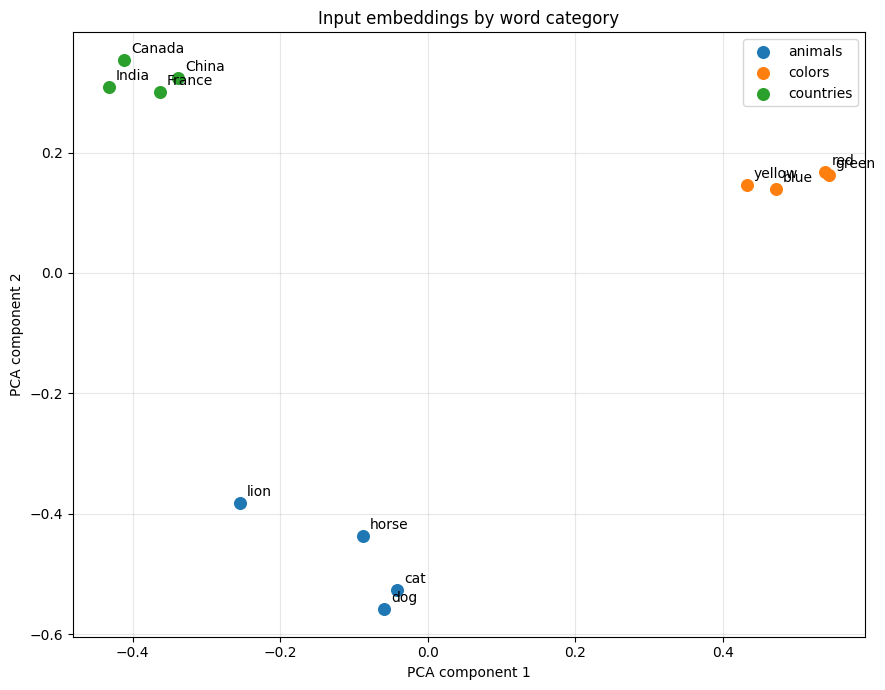

In [130]:
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

categories = {
    "animals": ["cat", "dog", "horse", "lion"],
    "colors": ["red", "blue", "green", "yellow"],
    "countries": ["India", "Canada", "China", "France"],
}

embedding_layer = model.get_input_embeddings()
device = embedding_layer.weight.device

def get_word_embedding(word):
    # 不添加 BOS 等特殊 token
    token_ids = tokenizer.encode(word, add_special_tokens=False)
    if not token_ids:
        raise ValueError(f"No tokens for {word!r}")

    # 顺便检查每个词被拆成了哪些 token
    print(f"{word:>8}: {tokenizer.convert_ids_to_tokens(token_ids)}")

    ids = torch.tensor([token_ids], device=device)

    with torch.no_grad():
        # [1, token数, 1024]
        embeddings = embedding_layer(ids)

        # 对 token 维度取平均，得到 [1024]
        return embeddings[0].float().mean(dim=0).cpu().numpy()

words = []
labels = []
vectors = []

for category, category_words in categories.items():
    for word in category_words:
        words.append(word)
        labels.append(category)
        vectors.append(get_word_embedding(word))

# 将高维向量投影到二维, (12, 768) -> (12, 2)
coordinates = PCA(n_components=2).fit_transform(vectors)

# 画散点图
plt.figure(figsize=(9, 7))

for category in categories:
    indices = [i for i, label in enumerate(labels) if label == category]

    plt.scatter(
        coordinates[indices, 0],
        coordinates[indices, 1],
        label=category,
        s=70
    )

    for i in indices:
        plt.annotate(
            words[i],
            (coordinates[i, 0], coordinates[i, 1]),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("Input embeddings by word category")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [148]:
category, indices, coordinates[indices, 0]

('countries',
 [8, 9, 10, 11],
 array([-0.4320043 , -0.41122638, -0.33831893, -0.36259374]))

### 4.2 Masked language modeling

In [74]:
from transformers import AutoModelForMaskedLM, AutoTokenizer, pipeline
from transformers import pipeline

# Load a fill-mask model (masked language model)
# Note: We use BERT here because Qwen is a causal model and can't do masked prediction

model_name = "bert-base-uncased"
cache_dir = "/root/.cache/huggingface/hub"

print("Loading masked language model (BERT)...")

tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    cache_dir=cache_dir,
)

model = AutoModelForMaskedLM.from_pretrained(
    model_name,
    cache_dir=cache_dir,
)

fill_mask = pipeline(
    "fill-mask",
    model=model,
    tokenizer=tokenizer,
    device=0 if torch.cuda.is_available() else -1,
)
# fill_mask = pipeline("fill-mask", model="bert-base-uncased")
print("✓ Model loaded!\n")

# Use sentences with strong contextual clues
sentences = [
    "The sky is [MASK].",
    "I drink [MASK] in the morning."
]

for sentence in sentences:
    print(f"Sentence: '{sentence}'")
    print("Top predictions:\n")
    
    results = fill_mask(sentence, top_k=3)
    
    for i, result in enumerate(results, 1):
        word = result['token_str'].strip()
        score = result['score']
        filled = result['sequence']
        print(f"  {i}. '{word}' ({score1%})")
        print(f"      → {filled}")
    
    print("\n" + "="*60 + "\n")

print("💡 Masked Language Modeling uses BOTH left AND right context, it sees the FULL sentence.")
print("   This makes it great for understanding.")

Loading masked language model (BERT)...


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cuda:0


✓ Model loaded!

Sentence: 'The sky is [MASK].'
Top predictions:

  1. 'clear' (20.1%)
      → the sky is clear.
  2. 'blue' (19.0%)
      → the sky is blue.
  3. 'dark' (13.3%)
      → the sky is dark.


Sentence: 'I drink [MASK] in the morning.'
Top predictions:

  1. 'it' (31.5%)
      → i drink it in the morning.
  2. 'coffee' (14.6%)
      → i drink coffee in the morning.
  3. 'beer' (4.8%)
      → i drink beer in the morning.


💡 Masked Language Modeling uses BOTH left AND right context, it sees the FULL sentence.
   This makes it great for understanding.


/opt/venv/lib/python3.12/site-packages/transformers/models/bert/modeling_bert.py:413: UserWarning: Using AOTriton backend for Efficient Attention forward... (Triggered internally at /app/pytorch/aten/src/ATen/native/transformers/hip/attention.hip:1452.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(


#### HeatMap of Attention

Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


层数： 12
第一层形状： torch.Size([1, 12, 9, 9])


/tmp/ipykernel_3337/972167649.py:43: UserWarning: Glyph 34987 (\N{CJK UNIFIED IDEOGRAPH-88AB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3337/972167649.py:43: UserWarning: Glyph 20851 (\N{CJK UNIFIED IDEOGRAPH-5173}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3337/972167649.py:43: UserWarning: Glyph 27880 (\N{CJK UNIFIED IDEOGRAPH-6CE8}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3337/972167649.py:43: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3337/972167649.py:43: UserWarning: Glyph 24403 (\N{CJK UNIFIED IDEOGRAPH-5F53}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3337/972167649.py:43: UserWarning: Glyph 21069 (\N{CJK UNIFIED IDEOGRAPH-524D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 24403 (\N{

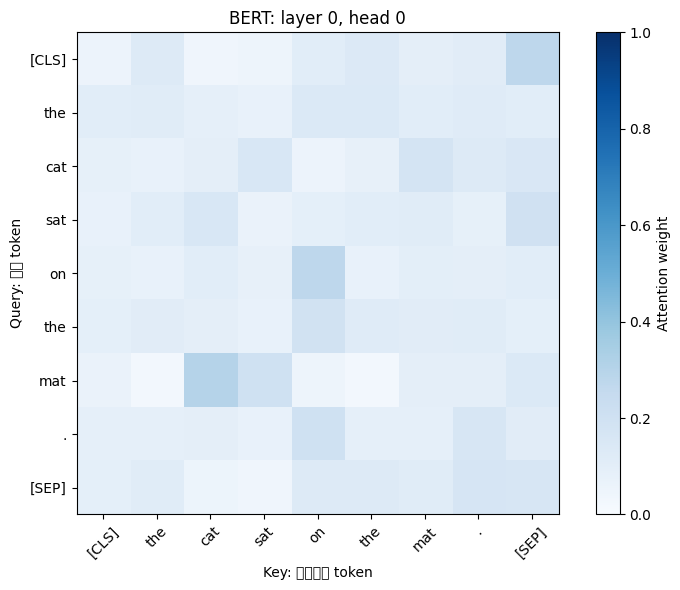

In [91]:
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

model_name = "bert-base-uncased"
cache_dir = "/root/.cache/huggingface/hub"

tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    cache_dir=cache_dir,
)

model = AutoModelForMaskedLM.from_pretrained(
    model_name,
    cache_dir=cache_dir,
)

model.eval()

text = "The cat sat on the mat."
inputs = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

# attentions：每一层有一个张量
print("层数：", len(outputs.attentions))
print("第一层形状：", outputs.attentions[0].shape)

# 第 0 层，第 0 个样本，第 0 个注意力头. 共12层，每层[1, 12, 9, 9]
attention = outputs.attentions[0][0, 0].cpu()

tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

plt.figure(figsize=(8, 6))
plt.imshow(attention, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Attention weight")
plt.xticks(range(len(tokens)), tokens, rotation=45)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("Key: 被关注的 token")
plt.ylabel("Query: 当前 token")
plt.title("BERT: layer 0, head 0")
plt.tight_layout()
plt.show()

### 5. pipeline

In [159]:
from transformers import AutoTokenizer, AutoModel
import torch

print("=" * 60)
print("COMPLETE TRANSFORMER PIPELINE WALKTHROUGH")
print("=" * 60)

# Setup - using Qwen3 for this demo

model_name = "Qwen/Qwen3-0.6B"
cache_dir = "/root/.cache/huggingface/hub"
tokenizer = AutoTokenizer.from_pretrained(model_name,  cache_dir=cache_dir)
model = AutoModel.from_pretrained(model_name,  cache_dir=cache_dir)

text = "the cat is orange"

print(f"\nUsing model: {model_name}")
print(f"Input Text: '{text}'\n")

# Step 1: Tokenization
print("Step 1: TOKENIZATION")
tokens = tokenizer.tokenize(text)
print(f"  Tokens: {tokens}\n")

# Step 2: Token IDs
print("Step 2: TOKEN IDs")
token_ids = tokenizer.encode(text, return_tensors="pt")
print(f"  Token IDs: {token_ids.tolist()[0]}\n")

# Step 3: Initial Embeddings
print("Step 3: EMBEDDINGS")
with torch.no_grad():
    embedding_layer = model.get_input_embeddings()
    embeddings = embedding_layer(token_ids)
print(f"  Shape: {embeddings.shape}")
print(f"  → {embeddings.shape[1]} tokens, {embeddings.shape[2]} dimensions each\n")

# Step 4: Attention + Context
print("Step 4: ATTENTION (running through all transformer layers)")
with torch.no_grad():
    outputs = model(token_ids, output_attentions=True)
print(f"  The model has {model.config.num_hidden_layers} transformer layers")
print(f"  Each layer has {model.config.num_attention_heads} attention heads\n")

# Step 5: Context-Aware Representations
print("Step 5: CONTEXT-AWARE REPRESENTATIONS")
contextual_embeddings = outputs.last_hidden_state
print(f"  Shape: {contextual_embeddings.shape}")
print(f"  → Same shape as input embeddings, but now context-aware!\n")

# Step 6: Could use for various tasks
print("Step 6: TASK-SPECIFIC OUTPUT")
print("  These contextual representations can now be used for:")
print("  ✓ Causal LM: Predict next token (Qwen3, GPT, Claude)")
print("  ✓ Masked LM: Predict missing token (requires encoder model like BERT)")
print("  ✓ Classification: Predict sentiment, topic, etc.")
print("  ✓ Question Answering: Find answer from a passage")
print("  ✓ And many more tasks!\n")

print("=" * 60)
print("That's the complete transformer workflow!")
print("=" * 60)

COMPLETE TRANSFORMER PIPELINE WALKTHROUGH


/opt/venv/lib/python3.12/site-packages/transformers/utils/generic.py:1014: UserWarning: `output_attentions=True` is not supported with `attn_implementation` other than ['eager', 'eager_paged', 'flex_attention']. Please use `model.set_attn_implementation('eager')` to enable capturing attention outputs.
  warnings.warn(
`sdpa` attention does not support `output_attentions=True` or `head_mask`. Please set your attention to `eager` if you want any of these features.



Using model: Qwen/Qwen3-0.6B
Input Text: 'the cat is orange'

Step 1: TOKENIZATION
  Tokens: ['the', 'Ġcat', 'Ġis', 'Ġorange']

Step 2: TOKEN IDs
  Token IDs: [1782, 8251, 374, 18575]

Step 3: EMBEDDINGS
  Shape: torch.Size([1, 4, 1024])
  → 4 tokens, 1024 dimensions each

Step 4: ATTENTION (running through all transformer layers)
  The model has 28 transformer layers
  Each layer has 16 attention heads

Step 5: CONTEXT-AWARE REPRESENTATIONS
  Shape: torch.Size([1, 4, 1024])
  → Same shape as input embeddings, but now context-aware!

Step 6: TASK-SPECIFIC OUTPUT
  These contextual representations can now be used for:
  ✓ Causal LM: Predict next token (Qwen3, GPT, Claude)
  ✓ Masked LM: Predict missing token (requires encoder model like BERT)
  ✓ Classification: Predict sentiment, topic, etc.
  ✓ Question Answering: Find answer from a passage
  ✓ And many more tasks!

That's the complete transformer workflow!


In [161]:
outputs.attentions